# Tema 8 · Clasificar: vecinos cercanos y regresión logística

Predecir categorías: primero por parecido, luego con probabilidades.

Este cuaderno es el tema 8 de la [ruta de aprendizaje de la OBIA](https://iabolivia.org/aprende/aprendizaje-automatico/): la teoría y los ejercicios de [la página del tema](https://iabolivia.org/aprende/aprendizaje-automatico/8-clasificar-vecinos-cercanos-y-regresion-logistica/), con todo su código. Ejecuta las celdas en orden, de arriba abajo (o *Entorno de ejecución → Ejecutar todas*).

Debajo de cada celda está la salida que dio cuando se escribió el tema. Al ejecutarla, la tuya puede variar en los últimos decimales. Las actividades interactivas están en la página del tema.

# Teoría

## La pregunta

En el tema 6 el modelo predecía un **número**: la nota de un examen. Pero muchas preguntas piden otra cosa. ¿Este correo es basura o no? ¿Este dígito escrito a mano es un 3 o un 8? ¿Este tumor es benigno o maligno? La respuesta no es un número cualquiera, sino una entre unas pocas **categorías**. Predecir una categoría se llama **clasificar**.

Hay dos ideas muy distintas para hacerlo. La primera es casi de sentido común: **mirar a los parecidos**. Si los casos más parecidos al nuevo eran todos benignos, probablemente este también lo sea. La segunda reutiliza todo lo que aprendiste en el tema 6: un modelo con pesos, una función de pérdida y el descenso de gradiente, pero que en lugar de un número devuelve una **probabilidad**.

En este tema vas a:

- explicar cómo decide el algoritmo de los **vecinos más cercanos** (k-NN) y qué cambia al mover *k*;
- explicar la función **sigmoide** y la **frontera de decisión** de la regresión logística;
- programar desde cero la **regresión logística** con la **entropía cruzada** y el descenso de gradiente;
- extenderla a varias clases con **softmax**;
- usar `KNeighborsClassifier` y `LogisticRegression` de scikit-learn.

Necesitas el descenso de gradiente del tema 6 (con la misma notación: pesos *w*, término independiente *b* (en inglés, *bias*), tasa de aprendizaje *α*) y la división en datos de entrenamiento y de validación del tema 7, «Generalizar: sobreajuste, validación y regularización». Del tema 5 vas a usar el logaritmo y la exponencial. Recuerda que `np.log` es el logaritmo natural, el que en el colegio se escribe ln; en este tema, «log» siempre es ese.

## Actividad: pinta las clases

Antes de cualquier fórmula, pinta. En el lienzo hay puntos de dos clases: círculos **tinta** y cuadrados **coral**. Elige la clase y toca el lienzo para poner un punto; toca un punto para quitarlo. El fondo muestra qué clase predice el modelo en cada lugar: cuanto más intenso el color, más seguro está.

> **Actividad interactiva:** está en la [página del tema](https://iabolivia.org/aprende/aprendizaje-automatico/8-clasificar-vecinos-cercanos-y-regresion-logistica/teoria/). Ábrela en el navegador para usarla.
Prueba esto, en orden:

1. En el modo **vecinos**, deja *k* = 1. Mira las islas que forma cada intruso (el cuadrado coral metido entre los círculos y el círculo tinta entre los cuadrados). ¿Cuántos puntos acierta? Sube *k* a 3, 5 y 15. ¿Qué pasa con las islas y con los aciertos?
2. Pon tres o cuatro puntos coral muy juntos en una esquina vacía. ¿Con qué *k* desaparecen del mapa?
3. Pasa al modo **logística**. Ahora la frontera es una **recta**. Mueve *w*₁, *w*₂ y *b* hasta que la entropía cruzada sea lo más chica que puedas. ¿Puedes acertar todos los puntos iniciales con una recta?
4. Pulsa «Dar 25 pasos» varias veces. La computadora baja la entropía cruzada siguiendo el gradiente, como la bola del tema 6. ¿Llega a algo parecido a lo tuyo?
5. Borra todo y pinta los círculos en el centro y los cuadrados alrededor, formando un anillo. Compara los dos modos: ¿cuál puede separar las clases?

Lo que acabas de ver es el tema en pequeño: **k-NN decide por parecido y su frontera puede tener cualquier forma; la regresión logística aprende una recta y, a cada lado, una probabilidad.**

## Clasificar es predecir una categoría

En **clasificación binaria** hay dos clases, que se anotan 0 y 1 (por ejemplo, «no es basura» y «es basura»). En **clasificación multiclase** hay más de dos, como los diez dígitos del 0 al 9. La forma más simple de medir un clasificador es la **tasa de aciertos** (en inglés, *accuracy*): la fracción de ejemplos en los que acierta la clase. En el tema 9 vas a ver por qué a veces no alcanza.

Empezamos con datos **sintéticos** en dos dimensiones, para poder dibujarlo todo. `make_moons` de scikit-learn genera dos medias lunas encajadas una en la otra, con ruido. Como en el tema 7, separamos una parte de los datos para **validar**: el modelo nunca la ve al entrenar, y con ella medimos cómo le va con datos nuevos.

Forma de X: (200, 2)
Primeras etiquetas: [0 1 1 0 1 1 0 1 0 1]
Entrenamiento: 140   validación: 60
Puntos de cada clase al entrenar: [68 72]


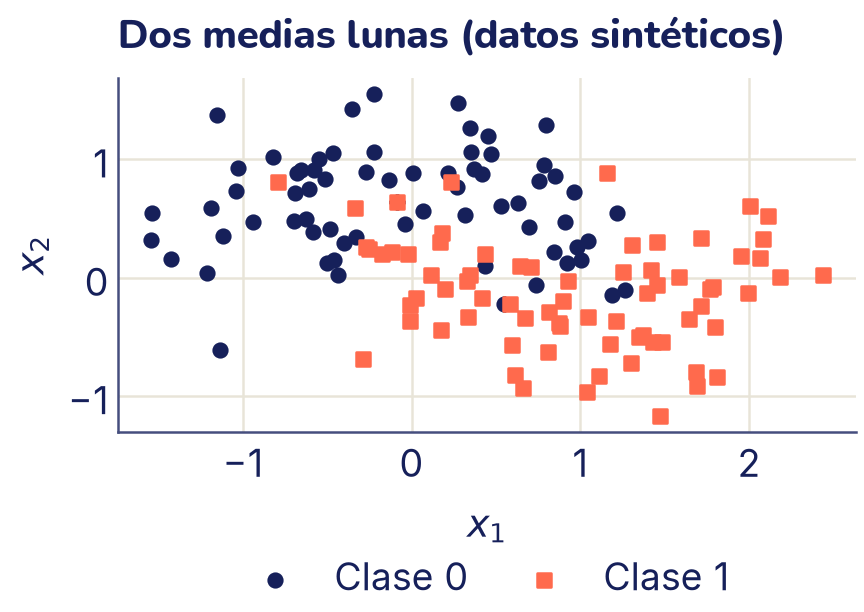

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

# 200 puntos sintéticos en dos clases con forma de media luna
X, y = make_moons(n_samples=200, noise=0.3, random_state=0)
# Como en el tema 7: 70 % para entrenar y 30 % para validar
X_entr, X_val, y_entr, y_val = train_test_split(
    X, y, test_size=0.3, random_state=0)

print("Forma de X:", X.shape)
print("Primeras etiquetas:", y[:10])
print("Entrenamiento:", len(y_entr), "  validación:", len(y_val))
print("Puntos de cada clase al entrenar:", np.bincount(y_entr))

def dibujar_clases(X, y, ax=None, s=30):
    """Clase 0: círculos de color C0. Clase 1: cuadrados de color C1."""
    # Si no te pasan un eje (ax), usa el del gráfico actual
    ax = ax or plt.gca()
    ax.scatter(X[y == 0, 0], X[y == 0, 1], s=s, color="C0",
               marker="o", label="Clase 0")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], s=s, color="C1",
               marker="s", label="Clase 1")

dibujar_clases(X_entr, y_entr)
# "$x_1$" escribe x con el subíndice 1
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Dos medias lunas (datos sintéticos)")
# La leyenda va debajo del gráfico, para no tapar puntos
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2,
           frameon=False, handlelength=1.6, columnspacing=1.2)
plt.show()

Cada fila de `X` es un ejemplo con dos **características**, *x*₁ y *x*₂; `y` dice a qué clase pertenece. Ninguna recta separa bien las dos lunas, y en el medio los puntos se mezclan: ningún modelo va a acertar todos.

## Vecinos cercanos: dime con quién andas

El algoritmo de los **k vecinos más cercanos** (*k-nearest neighbors*, k-NN) clasifica un punto nuevo así:

1. Mide la distancia del punto nuevo a **todos** los ejemplos de entrenamiento.
2. Se queda con los *k* más cercanos: sus vecinos.
3. Predice la clase que más se repite entre esos vecinos. Es una votación.

Para medir la distancia usamos la **distancia euclidiana**, la de la regla, que sale del teorema de Pitágoras. Entre dos puntos *a* y *c* con *d* características:

$$d ( \mathbf{a} , \mathbf{c} ) = \sqrt{\sum_{j = 1}^{d} {( {a}_{j} - {c}_{j} )}^{2}}$$

Programarlo cabe en pocas líneas. Con el *broadcasting* del tema 3, `X_entr - x` resta el punto `x` de todas las filas a la vez:

In [ ]:
def distancias(X_entr, x):
    """Distancia euclidiana de x a cada fila de X_entr."""
    return np.sqrt(np.sum((X_entr - x) ** 2, axis=1))

def knn_predecir(X_entr, y_entr, X_nuevos, k):
    """Para cada fila de X_nuevos, la clase que más se repite
    entre sus k vecinos más cercanos de X_entr."""
    predicciones = []
    for x in X_nuevos:
        d = distancias(X_entr, x)
        vecinos = np.argsort(d)[:k]   # índices de los k más cercanos
        votos = np.bincount(y_entr[vecinos])
        predicciones.append(np.argmax(votos))
    return np.array(predicciones)

nuevo = np.array([0.5, 0.25])
d = distancias(X_entr, nuevo)
cercanos = np.argsort(d)[:5]
print("Distancias de los 5 vecinos:", np.round(d[cercanos], 2))
print("Sus clases:", y_entr[cercanos])
print("Predicción con k = 5:",
      knn_predecir(X_entr, y_entr, [nuevo], k=5))

Distancias de los 5 vecinos: [0.08 0.17 0.21 0.26 0.27]
Sus clases: [1 0 1 0 1]
Predicción con k = 5: [1]


`np.argsort` devuelve los índices que ordenan las distancias de menor a mayor; los primeros *k* son los vecinos. `np.bincount` cuenta los votos de cada clase y `np.argmax` elige la más votada. Aquí ganó la clase 1 por tres votos contra dos.

Fíjate en algo raro: k-NN **no tiene parámetros que entrenar**. No hay pesos ni descenso de gradiente; «entrenar» es solo guardar los ejemplos, y todo el trabajo se hace al predecir. Por eso predecir es lento cuando hay muchos datos: para cada punto nuevo hay que medir la distancia a todos.

Midamos los aciertos en validación y comparemos con scikit-learn, que tiene la misma interfaz `fit`/`predict` del tema 6. Su método `score` devuelve directamente la tasa de aciertos:

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

pred_val = knn_predecir(X_entr, y_entr, X_val, k=5)
print("Aciertos en validación (nuestro):", np.mean(pred_val == y_val))

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_entr, y_entr)               # solo guarda los ejemplos
print("Aciertos en validación (scikit-learn):",
      knn.score(X_val, y_val))
print("¿Las mismas predicciones?",
      np.all(knn.predict(X_val) == pred_val))

Aciertos en validación (nuestro): 0.9333333333333333
Aciertos en validación (scikit-learn): 0.9333333333333333
¿Las mismas predicciones? True


### El efecto de k

¿Cuántos vecinos conviene mirar? Para verlo, clasificamos cada punto de una cuadrícula fina que cubre el plano: así aparecen las **regiones de decisión**, la zona del plano que el modelo asigna a cada clase. La línea donde se tocan es la **frontera de decisión**.

k =  1:  aciertos al entrenar 1.00   en validación 0.90
k =  5:  aciertos al entrenar 0.90   en validación 0.93
k = 25:  aciertos al entrenar 0.91   en validación 0.92
k = 75:  aciertos al entrenar 0.80   en validación 0.77


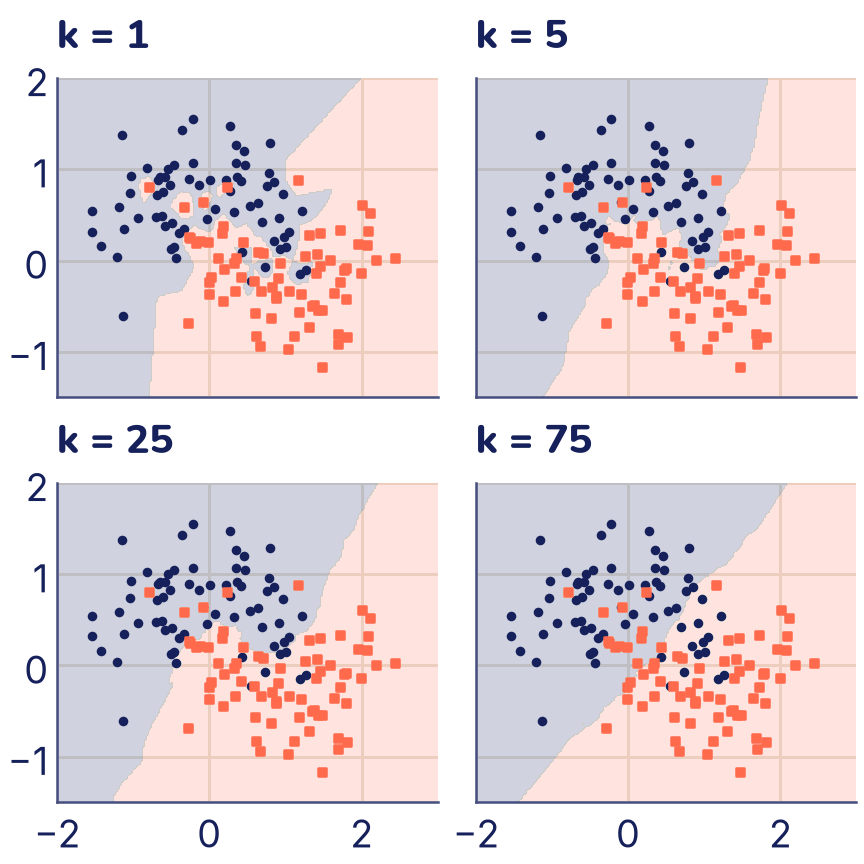

In [ ]:
# Una cuadrícula de 200 × 200 puntos que cubre el dibujo
A, B = np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-1.5, 2, 200))
rejilla = np.column_stack([A.ravel(), B.ravel()])   # 40 000 filas

fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8),
                         sharex=True, sharey=True)
for eje, k in zip(ejes.flat, [1, 5, 25, 75]):
    modelo_k = KNeighborsClassifier(n_neighbors=k).fit(X_entr, y_entr)
    zona = modelo_k.predict(rejilla).reshape(A.shape)
    # Cada región, del color de su clase y muy clara
    eje.contourf(A, B, zona, levels=[-0.5, 0.5, 1.5],
                 colors=["C0", "C1"], alpha=0.2)
    dibujar_clases(X_entr, y_entr, ax=eje, s=8)
    eje.set_title(f"k = {k}")
    print(f"k = {k:2d}:  aciertos al entrenar "
          f"{modelo_k.score(X_entr, y_entr):.2f}"
          f"   en validación {modelo_k.score(X_val, y_val):.2f}")
plt.show()

Es el sobreajuste y el subajuste del tema 7, ahora con clases:

- Con **k = 1**, cada punto de entrenamiento es su propio vecino más cercano, así que acierta el 100 % al entrenar. Pero la frontera rodea cada punto suelto, aunque sea ruido, y en validación le va peor. El modelo **memorizó**.
- Con **k = 75**, más de la mitad de los 140 ejemplos votan siempre. La frontera queda casi recta y ya no sigue la forma de las lunas. El modelo es **demasiado simple**.
- En el medio, con *k* = 5 o 25, la frontera sigue la forma de los datos sin perseguir cada punto.

*k* es un **hiperparámetro**: no se aprende de los datos, lo eliges tú. Se elige como en el tema 7, probando varios valores y mirando los aciertos en **validación**, nunca al entrenar. Con dos clases conviene un *k* impar, para que la votación no empate.

### Escalar importa

La distancia suma las diferencias de todas las características, así que una característica con números grandes manda sobre las demás. Imagina dos personas descritas por su estatura en metros (1,60 y 1,80) y su ingreso mensual en bolivianos (3000 y 3100). La diferencia de estatura aporta 0,2 a la distancia; la de ingreso, 100. Para k-NN, esas dos personas se parecen o no solo según su ingreso, y la estatura no cuenta para nada.

La solución es la **estandarización** del tema 5: a cada columna se le resta su media y se la divide por su desviación estándar, calculadas **solo con los datos de entrenamiento** (si usas también la validación, se filtra información de los datos que deberían ser nuevos). Así todas las características quedan en la misma escala. En el ejercicio 4 vas a medir cuánto cambia esto los aciertos con datos reales.

### Demasiadas dimensiones

Con dos características, «cerca» y «lejos» son claros. Con cientos, pasa algo inesperado: **todas las distancias se parecen**. Probémoslo con 500 puntos al azar dentro de un cubo de *d* dimensiones, midiendo la distancia del primero a los demás:

In [ ]:
rng = np.random.default_rng(0)
for dim in [2, 10, 100, 1000]:
    puntos = rng.uniform(0, 1, size=(500, dim))
    dist = distancias(puntos[1:], puntos[0])
    print(f"{dim:4d} dimensiones:  más cercano {dist.min():6.2f}"
          f"   más lejano {dist.max():6.2f}"
          f"   cociente {dist.min() / dist.max():.2f}")

   2 dimensiones:  más cercano   0.01   más lejano   0.94   cociente 0.01
  10 dimensiones:  más cercano   0.58   más lejano   1.92   cociente 0.30
 100 dimensiones:  más cercano   3.63   más lejano   4.95   cociente 0.73
1000 dimensiones:  más cercano  12.29   más lejano  13.62   cociente 0.90


En dos dimensiones, el vecino más cercano está muchísimo más cerca que el más lejano: el cociente es casi 0. En mil, el más cercano está casi tan lejos como el más lejano: la palabra «vecino» pierde su sentido. A esto se le llama la **maldición de la dimensión**. Por eso k-NN funciona bien con pocas características (en el tema 15 vas a ver por qué muchos datos reales se comportan como si tuvieran pocas dimensiones) y mal con muchas columnas al azar.

## Regresión logística: una probabilidad en lugar de un voto

k-NN tiene dos inconvenientes: hay que guardar todos los ejemplos para predecir y no da una fórmula que se pueda leer. Volvamos a la idea del tema 6: un modelo con pesos que se aprenden. Con dos características, el **puntaje** de un punto es

$$z = {w}_{1} {x}_{1} + {w}_{2} {x}_{2} + b$$

exactamente la regresión lineal del tema 6. El problema es que *z* puede ser cualquier número, como −7 o 250, y nosotros queremos una **probabilidad** de que el punto sea de la clase 1, un número entre 0 y 1. La solución es pasar *z* por una función que aplaste todos los números a ese rango: la **sigmoide**.

$$\sigma ( z ) = \frac{1}{1 + {e}^{- z}}$$

z = -6   ->   sigmoide(z) = 0.002
z = -2   ->   sigmoide(z) = 0.119
z =  0   ->   sigmoide(z) = 0.500
z =  2   ->   sigmoide(z) = 0.881
z =  6   ->   sigmoide(z) = 0.998


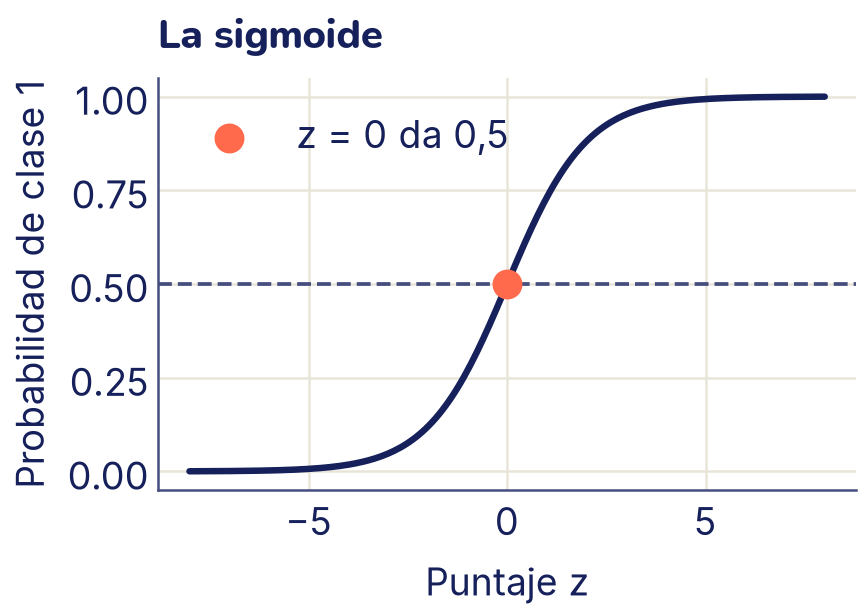

In [ ]:
def sigmoide(z):
    """Aplasta cualquier número a un valor entre 0 y 1."""
    return 1 / (1 + np.exp(-z))

for z in [-6, -2, 0, 2, 6]:
    print(f"z = {z:2d}   ->   sigmoide(z) = {sigmoide(z):.3f}")

zs = np.linspace(-8, 8, 200)
plt.plot(zs, sigmoide(zs), color="C0")
plt.axhline(0.5, color="C2", linestyle="--", linewidth=1.5)
plt.scatter([0], [0.5], color="C1", s=120, zorder=3,
            label="z = 0 da 0,5")
plt.xlabel("Puntaje z")
plt.ylabel("Probabilidad de clase 1")
plt.title("La sigmoide")
plt.legend(loc="upper left")
plt.show()

Lee la curva así: un puntaje muy negativo da una probabilidad casi 0 (casi seguro clase 0); uno muy positivo, casi 1 (casi seguro clase 1); y un puntaje 0 da exactamente 0,5, la duda total. Al juntar las dos piezas tenemos la **regresión logística**: *p* = σ(*w*₁*x*₁ + *w*₂*x*₂ + *b*). A pesar del nombre, es un modelo de **clasificación**.

### El puntaje son las chances, en logaritmo

¿Qué significa *z*? Si la probabilidad de la clase 1 es *p*, las **chances** (en inglés, *odds*) son *p* / (1 − *p*): con *p* = 0,8, las chances son 0,8 / 0,2 = 4, que se lee «4 a 1»: por cada 4 veces que pasa, hay 1 que no. **Ojo: las chances no son la probabilidad.** En el habla de todos los días «chance» se usa como probabilidad, pero aquí es otra cosa: la probabilidad va de 0 a 1, y las chances, de 0 a infinito (con *p* = 0,5 son 1, «1 a 1»).

De la sigmoide, *p* = 1 / (1 + *e*<sup>−*z*</sup>), se puede despejar *z* en cuatro pasos:

1. Invierte los dos lados (1 dividido entre cada uno): 1 / *p* = 1 + *e*<sup>−*z*</sup>.
2. Resta 1 a los dos lados: 1 / *p* − 1 = (1 − *p*) / *p* = *e*<sup>−*z*</sup>.
3. Invierte otra vez los dos lados: *p* / (1 − *p*) = *e*<sup>*z*</sup>.
4. Saca el logaritmo natural a los dos lados (deshace la exponencial).

Sale que *z* es el logaritmo de las chances, llamado **log-odds** (en inglés; en español, «logaritmo de las chances»):

$$z = \log \frac{p}{1 - p}$$

In [ ]:
z = 1.5
p = sigmoide(z)
chances = p / (1 - p)
print(f"p = {p:.3f}   chances = {chances:.3f}"
      f"   log(chances) = {np.log(chances):.3f}")

p = 0.818   chances = 4.482   log(chances) = 1.500


La regresión logística es entonces una **recta para el logaritmo de las chances**. Cada peso dice cuánto suben (o bajan, si es negativo) los log-odds cuando su característica sube en 1.

### La frontera de decisión es una recta

Para decidir una clase hace falta una regla. La usual es predecir clase 1 si *p* ≥ 0,5. Como σ(*z*) = 0,5 justo cuando *z* = 0, la frontera entre las dos regiones es

$${w}_{1} {x}_{1} + {w}_{2} {x}_{2} + b = 0$$

que es la ecuación de una **recta** en el plano (con más características, un plano o su versión en más dimensiones). Por eso se dice que la regresión logística es un **clasificador lineal**: es la recta que movías con los deslizadores en la actividad. Lejos de la recta, la probabilidad se acerca a 0 o a 1; cerca, a 0,5.

## Medir el error: la entropía cruzada

Para entrenar con descenso de gradiente necesitamos una función de pérdida. La idea es castigar al modelo según la **probabilidad que le dio a la clase correcta**: si dijo 0,99 y acertó, casi nada; si dijo 0,01, muchísimo. La pérdida que hace eso es el **logaritmo negativo** de esa probabilidad, y su promedio se llama **entropía cruzada binaria**:

$$L = - \frac{1}{n} \sum_{i = 1}^{n} [ {y}_{i} \log {p}_{i} + ( 1 - {y}_{i} ) \log ( 1 - {p}_{i} ) ]$$

Parece complicada, pero en cada ejemplo solo sobrevive uno de los dos términos: si *y* = 1 queda −log *p* (la probabilidad que dio a la clase 1), y si *y* = 0 queda −log(1 − *p*) (la que dio a la clase 0). Comparémosla con el error al cuadrado, que sería la opción del tema 6:

*La celda que sigue da un error a propósito: es parte de la explicación.*

Prob. dada a la clase correcta: [0.99 0.9  0.5  0.1  0.01]
Entropía cruzada, -log(p):      [0.01 0.11 0.69 2.3  4.61]
Error al cuadrado, (1 - p)²:    [0.   0.01 0.25 0.81 0.98]


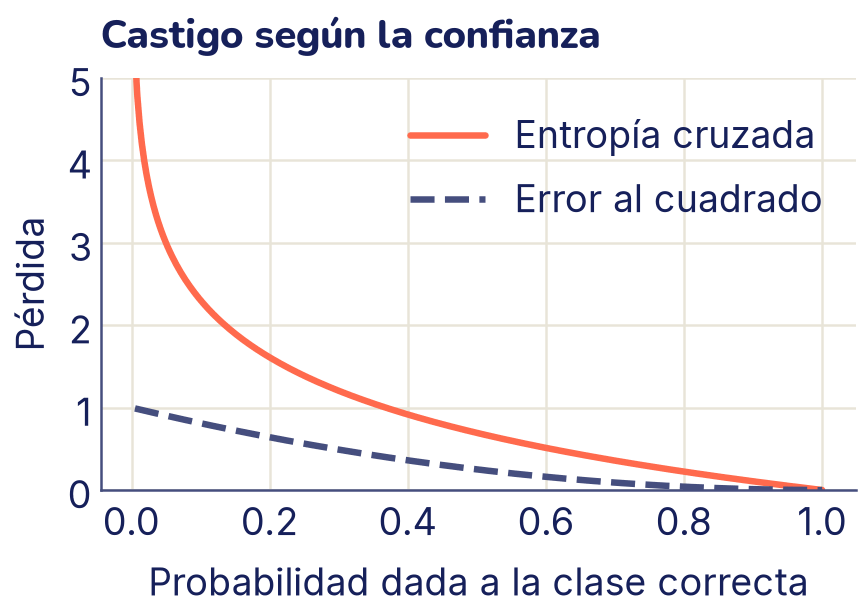

In [ ]:
p_correcta = np.array([0.99, 0.9, 0.5, 0.1, 0.01])
print("Prob. dada a la clase correcta:", p_correcta)
print("Entropía cruzada, -log(p):     ",
      np.round(-np.log(p_correcta), 2))
print("Error al cuadrado, (1 - p)²:   ",
      np.round((1 - p_correcta) ** 2, 2))

ps = np.linspace(0.005, 1, 300)
plt.plot(ps, -np.log(ps), color="C1", label="Entropía cruzada")
plt.plot(ps, (1 - ps) ** 2, color="C2", linestyle="--",
         label="Error al cuadrado")
plt.ylim(0, 5)
plt.xlabel("Probabilidad dada a la clase correcta")
plt.ylabel("Pérdida")
plt.title("Castigo según la confianza")
plt.legend()
plt.show()

¿Por qué no usar el MSE como en el tema 6? Por dos razones:

- **El error al cuadrado no pasa de 1.** Un modelo que dice «0,01 de que sea maligno» cuando el tumor sí lo era se equivocó gravísimo, pero el error al cuadrado solo le cobra 0,98, casi lo mismo que a uno que dijo 0,1. La entropía cruzada le cobra 4,61: el castigo crece sin límite cuanto más seguro está el modelo de algo falso.
- **Con la sigmoide, el MSE aprende muy despacio justo cuando más se equivoca.** Si *z* es muy negativo y la clase era 1, la sigmoide está en su parte plana y el gradiente del MSE es casi cero: la bola queda en una meseta. En el ejercicio 6 lo vas a ver con números.

Hay una tercera razón, más de fondo, que conecta con el tema 5. La probabilidad de que el modelo acierte **todos** los ejemplos de entrenamiento es el producto de las probabilidades que dio a cada clase correcta. Maximizar ese producto es lo mismo que maximizar la suma de sus logaritmos (porque el logaritmo siempre crece: el producto más grande tiene también la suma de logaritmos más grande), y eso es lo mismo que minimizar la entropía cruzada. Es la regla del logaritmo que convierte productos en sumas.

## Programar la logística desde cero

Necesitamos el gradiente de la entropía cruzada. Con la regla de la cadena (lo haces paso a paso en el ejercicio 3) sale un resultado sorprendentemente simple:

$$\frac{\partial L}{\partial {w}_{j}} = \frac{1}{n} \sum_{i = 1}^{n} ( {p}_{i} - {y}_{i} ) \cdot {x}_{i j} \qquad \frac{\partial L}{\partial b} = \frac{1}{n} \sum_{i = 1}^{n} ( {p}_{i} - {y}_{i} )$$

Compáralo con el gradiente del MSE del tema 6: es la misma forma, «el error (predicho menos real) por *x*, promediado», solo que el error ahora es una probabilidad menos una etiqueta 0 o 1, y no aparece el 2. La derivada de la sigmoide se cancela con la del logaritmo; por eso la pareja sigmoide y entropía cruzada funciona tan bien.

El descenso de gradiente es el mismo bucle del tema 6, escrito con matrices como en `descenso_gradiente_varias`:

In [ ]:
def entropia_cruzada(y, p):
    """Entropía cruzada binaria promedio."""
    # Un recorte mínimo evita log(0) si alguna p llega a 0 o a 1
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def descenso_logistica(X, y, tasa, pasos):
    """Regresión logística con descenso de gradiente.

    Devuelve los pesos w, el término independiente b y la pérdida
    antes de cada paso.
    """
    n, d = X.shape
    w = np.zeros(d)                   # un peso por característica
    b = 0.0
    historial = []
    for paso in range(pasos):
        p = sigmoide(X @ w + b)       # probabilidad de la clase 1
        historial.append(entropia_cruzada(y, p))
        error = p - y                 # predicho menos real
        w = w - tasa * X.T @ error / n
        b = b - tasa * np.mean(error)
    return w, b, np.array(historial)

w_log, b_log, perdidas = descenso_logistica(X_entr, y_entr,
                                            tasa=0.5, pasos=3000)
for paso in [0, 10, 100, 1000, 2999]:
    print(f"Paso {paso:4d}:   entropía cruzada = {perdidas[paso]:.4f}")
print("w =", np.round(w_log, 3), "  b =", round(b_log, 3))

Paso    0:   entropía cruzada = 0.6931
Paso   10:   entropía cruzada = 0.4777
Paso  100:   entropía cruzada = 0.3778
Paso 1000:   entropía cruzada = 0.3717
Paso 2999:   entropía cruzada = 0.3717
w = [ 1.154 -3.133]   b = 0.33


Al empezar, con todos los pesos en cero, el modelo dice 0,5 para todos y la pérdida es −log 0,5 ≈ 0,693. Baja rápido y hacia el paso 1000 ya no cambia (se queda en 0,3717): el descenso convergió. El peso de *x*₂ es grande y negativo: cuanto más arriba está un punto, menos probable es que sea de la clase 1, que es la luna de abajo.

Ahora comparemos con scikit-learn. Ojo: `LogisticRegression` usa por defecto una **regularización** como la de Ridge del tema 7, que achica los pesos. Para comparar con nuestro descenso, que no la tiene, la apagamos con `C=np.inf` (`C` es el inverso de la fuerza de la regularización):

In [ ]:
from sklearn.linear_model import LogisticRegression

def predecir_clase(X, w, b, umbral=0.5):
    """Clase 1 si la probabilidad llega al umbral; si no, clase 0."""
    return (sigmoide(X @ w + b) >= umbral).astype(int)

# C=np.inf: sin regularización, para comparar con nuestro descenso
logistica = LogisticRegression(C=np.inf).fit(X_entr, y_entr)
print("scikit-learn:  w =", np.round(logistica.coef_[0], 3),
      "  b =", np.round(logistica.intercept_[0], 3))
aciertos = np.mean(predecir_clase(X_val, w_log, b_log) == y_val)
print("Aciertos en validación (nuestro):", round(aciertos, 3))
print("Aciertos en validación (scikit-learn):",
      round(logistica.score(X_val, y_val), 3))

scikit-learn:  w = [ 1.153 -3.131]   b = 0.331
Aciertos en validación (nuestro): 0.85
Aciertos en validación (scikit-learn): 0.85


Los mismos pesos, salvo en la tercera cifra decimal, y los mismos aciertos. Dibujemos la probabilidad que da el modelo en cada lugar del plano. En vez de un degradado, la pintamos en **bandas**: cada banda junta los lugares con probabilidades parecidas, como las curvas de nivel del tema 6.

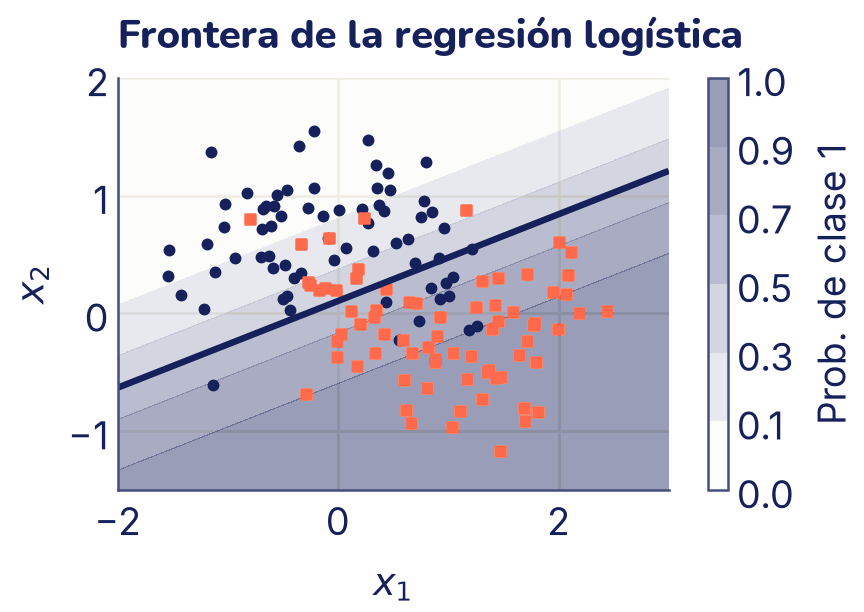

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

blanco_tinta = LinearSegmentedColormap.from_list("bt", ["white", "C0"])
prob = sigmoide(rejilla @ w_log + b_log).reshape(A.shape)

bandas = plt.contourf(A, B, prob, levels=[0, 0.1, 0.3, 0.5, 0.7, 0.9, 1],
                      cmap=blanco_tinta, alpha=0.45)
plt.contour(A, B, prob, levels=[0.5], colors="C0", linewidths=2.6)
dibujar_clases(X_entr, y_entr, s=14)
plt.colorbar(bandas, label="Prob. de clase 1")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Frontera de la regresión logística")
plt.show()

Las bandas son paralelas a la frontera, porque la probabilidad solo depende de la distancia a la recta. Y se ve el límite del modelo: con dos lunas encajadas, ninguna recta puede separarlas, y las puntas de cada luna quedan del lado equivocado. La logística acierta el 85 % en validación; k-NN, con su frontera curva, acertaba el 93 %. Un modelo lineal no es peor siempre: es mejor cuando las clases se separan bien con una recta, y además es rápido y se puede leer. En los temas siguientes vas a ver modelos con fronteras curvas que sí se entrenan con pesos.

## Varias clases: softmax

¿Y si hay más de dos clases, como los dígitos del 0 al 9? La idea se generaliza así: el modelo calcula **un puntaje por clase**, *z*₁, *z*₂, …, *z*<sub>K</sub>, cada uno con sus propios pesos, y los convierte en probabilidades con la función **softmax**:

$${p}_{k} = \frac{{e}^{{z}_{k}}}{\sum_{j = 1}^{K} {e}^{{z}_{j}}}$$

La exponencial vuelve positivos todos los puntajes, y dividir por la suma hace que las probabilidades sumen 1. El puntaje más alto se lleva la probabilidad más alta. La pérdida es la **entropía cruzada categórica**: otra vez, menos el logaritmo de la probabilidad que el modelo dio a la clase correcta, promediado.

In [ ]:
def softmax(z):
    """Convierte un puntaje por clase en probabilidades que suman 1."""
    # Restar el máximo no cambia el resultado y evita
    # que np.exp desborde con puntajes grandes
    e = np.exp(z - np.max(z))
    return e / e.sum()

puntajes = np.array([2.0, 1.0, 0.1])
probs = softmax(puntajes)
print("Probabilidades:", np.round(probs, 3), "  suman", probs.sum())
print("Entropía cruzada si la correcta es la primera:",
      round(-np.log(probs[0]), 3))
# Con dos clases, softmax es la sigmoide de la diferencia
print(round(softmax(np.array([1.5, 0.0]))[0], 6),
      round(sigmoide(1.5), 6))

Probabilidades: [0.659 0.242 0.099]   suman 1.0
Entropía cruzada si la correcta es la primera: 0.417
0.817574 0.817574


La última línea muestra que softmax con dos clases es exactamente la sigmoide: la regresión logística binaria es un caso particular.

### Dígitos escritos a mano

scikit-learn trae, sin descargar nada, 1797 imágenes de dígitos escritos a mano de 8 × 8 píxeles, con valores de 0 a 16. Cada imagen se aplana en una fila de 64 números (como en el tema 3) y la dividimos por 16 para que quede entre 0 y 1. `LogisticRegression` usa softmax sola cuando hay más de dos clases. Aquí dejamos su regularización por defecto, que ayuda con 64 características:

In [ ]:
from sklearn.datasets import load_digits

digitos = load_digits()
print("Imágenes:", digitos.images.shape)
Xd = digitos.data / 16                # 64 píxeles entre 0 y 1
yd = digitos.target                   # el dígito, de 0 a 9
Xd_entr, Xd_val, yd_entr, yd_val = train_test_split(
    Xd, yd, test_size=0.3, random_state=0)

log_digitos = LogisticRegression(max_iter=1000).fit(Xd_entr, yd_entr)
print("Aciertos en validación:",
      round(log_digitos.score(Xd_val, yd_val), 3))
proba = log_digitos.predict_proba(Xd_val[:1])
print("Probabilidades del primer dígito, de 0 a 9:")
print(np.round(proba[0], 3))
print("Es un", yd_val[0], " y el modelo dice",
      log_digitos.predict(Xd_val[:1])[0])

Imágenes: (1797, 8, 8)
Aciertos en validación: 0.961
Probabilidades del primer dígito, de 0 a 9:
[0.    0.001 0.996 0.001 0.    0.    0.    0.001 0.    0.   ]
Es un 2  y el modelo dice 2


`predict_proba` devuelve una fila por imagen y una columna por clase; `max_iter=1000` le da más pasos al optimizador para que converja. El modelo acierta el 96 % de los dígitos que nunca vio. Miremos algunos de los que falla:

Mal clasificados: 21 de 540


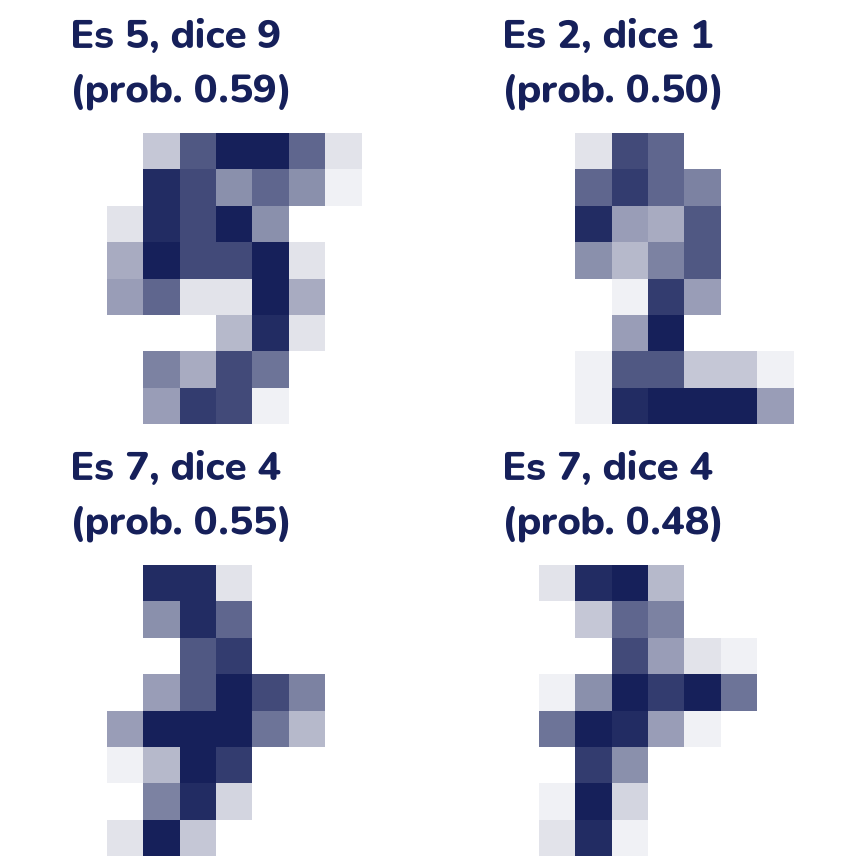

In [ ]:
pred_digitos = log_digitos.predict(Xd_val)
malos = np.flatnonzero(pred_digitos != yd_val)
print("Mal clasificados:", len(malos), "de", len(yd_val))

fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8))
for eje, i in zip(ejes.flat, malos[:4]):
    # blanco_tinta: la escala de blanco a tinta de la figura anterior
    eje.imshow(Xd_val[i].reshape(8, 8), cmap=blanco_tinta)
    p_max = log_digitos.predict_proba(Xd_val[i:i + 1]).max()
    eje.set_title(f"Es {yd_val[i]}, dice {pred_digitos[i]}\n"
                  f"(prob. {p_max:.2f})")
    eje.axis("off")
plt.show()

Con solo 64 píxeles, varios de estos dígitos son difíciles incluso para una persona. Fíjate en la probabilidad de cada error: un modelo útil suele dudar más (probabilidades más bajas) en los casos que falla.

## La probabilidad y el umbral

Hasta aquí convertimos la probabilidad en clase con el umbral 0,5. Pero ese umbral es una **decisión**, no una ley de la naturaleza. Veámoslo con datos reales incluidos en scikit-learn: 569 tumores de mama, cada uno descrito por 30 medidas de sus células en una imagen de microscopio, y etiquetados como **maligno (0)** o **benigno (1)**. Las medidas tienen escalas muy distintas, así que las estandarizamos con la media y la desviación del entrenamiento:

In [ ]:
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()
Xc, yc = cancer.data, cancer.target   # 0 = maligno, 1 = benigno
print("Forma:", Xc.shape, "  clases:", cancer.target_names,
      "  cuántos:", np.bincount(yc))
Xc_entr, Xc_val, yc_entr, yc_val = train_test_split(
    Xc, yc, test_size=0.3, random_state=0)

# Estandarizar con la media y la desviación del ENTRENAMIENTO
media, desv = Xc_entr.mean(axis=0), Xc_entr.std(axis=0)
Xc_entr_e = (Xc_entr - media) / desv
Xc_val_e = (Xc_val - media) / desv

log_cancer = LogisticRegression().fit(Xc_entr_e, yc_entr)
print("Aciertos en validación:",
      round(log_cancer.score(Xc_val_e, yc_val), 3))
# Columna 0 de predict_proba: probabilidad de la clase 0, maligno
p_maligno = log_cancer.predict_proba(Xc_val_e)[:, 0]
print("P(maligno) de los 5 primeros:", np.round(p_maligno[:5], 3))

Forma: (569, 30)   clases: ['malignant' 'benign']   cuántos: [212 357]
Aciertos en validación: 0.977
P(maligno) de los 5 primeros: [0.999 0.04  0.001 0.01  0.   ]


En este problema, los dos errores posibles no cuestan lo mismo. Decir «benigno» a un tumor maligno puede retrasar un tratamiento; decir «maligno» a uno benigno lleva a más estudios, que molestan pero no son graves. Contemos los dos tipos de error para tres umbrales: una alarma salta cuando P(maligno) llega al umbral.

In [ ]:
malignos = yc_val == 0
for umbral in [0.5, 0.2, 0.1]:
    alarma = p_maligno >= umbral
    no_detectados = np.sum(malignos & ~alarma)
    falsas_alarmas = np.sum(~malignos & alarma)
    print(f"Umbral {umbral}:  malignos sin detectar {no_detectados}"
          f"   falsas alarmas {falsas_alarmas}")

Umbral 0.5:  malignos sin detectar 3   falsas alarmas 1
Umbral 0.2:  malignos sin detectar 1   falsas alarmas 8
Umbral 0.1:  malignos sin detectar 1   falsas alarmas 17


Bajar el umbral detecta más malignos a cambio de más falsas alarmas. Ningún umbral es «el correcto»: depende de cuánto cuesta cada error, y eso lo decide quien usa el modelo, no el modelo. Por eso conviene que un clasificador dé **probabilidades** y no solo clases. En el tema 9 vas a medir esto con más cuidado, con la matriz de confusión y la curva ROC.

Un aviso importante: esto es un ejercicio de aprendizaje con un conjunto de datos público. Un modelo así no reemplaza el diagnóstico de un profesional de la salud.

## Lo que aprendiste y lo que sigue

- **Clasificar** es predecir una categoría. Con dos clases es **binaria**; con más, **multiclase**. La forma más simple de medirlo es la **tasa de aciertos**, siempre en datos de **validación**.
- **k-NN** predice la clase más votada entre los *k* ejemplos más cercanos según la **distancia euclidiana**. No entrena pesos: guarda los datos. Un *k* chico memoriza (sobreajuste) y uno grande simplifica de más (subajuste). Hay que **escalar** las características, y con muchas dimensiones las distancias se parecen todas.
- La **regresión logística** pasa el puntaje lineal *z* = *w*·*x* + *b* por la **sigmoide** y obtiene una probabilidad. *z* es el logaritmo de las chances, y la **frontera** *z* = 0 es una recta.
- Se entrena minimizando la **entropía cruzada** con descenso de gradiente. Su gradiente, (*p* − *y*) por *x* promediado, tiene la misma forma que el del MSE en la regresión lineal.
- Con varias clases, **softmax** convierte un puntaje por clase en probabilidades que suman 1.
- `predict_proba` da las probabilidades; el umbral 0,5 es una **decisión** que se ajusta según el costo de cada error.

La pareja «puntaje lineal más una función que lo transforma» es exactamente una **neurona artificial**. En el tema 16 vas a juntar muchas en capas y obtener fronteras curvas; la última capa de casi toda red que clasifica es una softmax entrenada con entropía cruzada.

# Ejercicios

## Antes de empezar

Varios ejercicios usan las variables y funciones de la teoría: `X_entr`, `X_val`, `y_entr`, `y_val` (las dos lunas), `distancias`, `knn_predecir`, `sigmoide`, `entropia_cruzada`, `softmax`, y los datos de los tumores (`Xc_entr`, `Xc_val`, `yc_entr`, `yc_val` y sus versiones estandarizadas `Xc_entr_e` y `Xc_val_e`). En este cuaderno, ejecuta las celdas de la teoría y trabaja en los ejercicios, que vienen debajo. Intenta cada ejercicio antes de abrir la respuesta.

## Ejercicios

### 1. ¿Clasificación o regresión?

Para cada situación, di si es un problema de **regresión** (predecir un número) o de **clasificación**, y en ese caso si es **binaria** o **multiclase**:

1. Predecir cuántos milímetros va a llover mañana.
2. Decidir si un mensaje es basura o no.
3. Reconocer qué letra del alfabeto está escrita en una imagen.
4. Predecir si un estudiante va a aprobar un examen.
5. Predecir la nota que va a sacar ese estudiante.

<details>
<summary>Respuesta</summary>

1. **Regresión**: la respuesta es una cantidad.
2. **Clasificación binaria**: basura o no.
3. **Clasificación multiclase**: una clase por letra.
4. **Clasificación binaria**: aprueba o no.
5. **Regresión**, como en el tema 6. Fíjate en que 4 y 5 hablan de lo mismo: muchas veces se puede plantear un problema de las dos formas, según qué respuesta sirve más.

</details>

### 2. Vecinos a mano

Seis ejemplos de entrenamiento con dos características:

| Punto | *x*₁ | *x*₂ | Clase |
|---|---|---|---|
| A | 1 | 1 | 1 |
| B | 2 | 1 | 0 |
| C | 4 | 3 | 1 |
| D | 5 | 4 | 1 |
| E | 3 | 2,5 | 1 |
| F | 0,5 | 3 | 0 |

a) Calcula sin computadora la distancia euclidiana de cada uno al punto nuevo (2,5; 1,5).

b) ¿Qué clase predice k-NN con *k* = 1, con *k* = 3 y con *k* = 5?

c) Compruébalo con `distancias` y `knn_predecir` de la teoría.

<details>
<summary>Respuesta</summary>

a) Por ejemplo, para B: √((2 − 2,5)² + (1 − 1,5)²) = √(0,25 + 0,25) = √0,5 ≈ 0,71. Ordenadas de menor a mayor: B 0,71; E 1,12; A 1,58; C 2,12; F 2,50; D 3,54.

b) Con *k* = 1, el más cercano es B: **clase 0**. Con *k* = 3 votan B, E y A: un voto para la clase 0 y dos para la 1, así que **clase 1**. Con *k* = 5 se suman C (1) y F (0): tres contra dos, **clase 1**. El mismo punto cambia de clase según cuántos vecinos se miran.

c)

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
P = np.array([[1, 1], [2, 1], [4, 3], [5, 4], [3, 2.5], [0.5, 3]])
clases = np.array([1, 0, 1, 1, 1, 0])
nuevo = np.array([2.5, 1.5])
print("Distancias:", np.round(distancias(P, nuevo), 2))
for k in [1, 3, 5]:
    print(f"k = {k}:", knn_predecir(P, clases, [nuevo], k))

### 3. El gradiente de la entropía cruzada (guiado)

*Opcional, para quienes se sienten cómodos con la regla de la cadena (la tabla de derivadas está en el tema 5).* Vamos a deducir, para **un solo ejemplo**, el gradiente que usa `descenso_logistica`. La pérdida de un ejemplo es *L* = −[*y* log *p* + (1 − *y*) log(1 − *p*)], con *p* = σ(*z*) y *z* = *w*·*x* + *b*.

a) La derivada de la sigmoide. Escribe σ(*z*) = (1 + *e*<sup>−*z*</sup>)<sup>−1</sup> y usa la regla de la cadena para mostrar que σ′(*z*) = σ(*z*) · (1 − σ(*z*)). Pista: al final, escribe *e*<sup>−*z*</sup> / (1 + *e*<sup>−*z*</sup>) como 1 − σ(*z*).

b) La derivada de *L* respecto de *p*. Recuerda que la derivada de log *p* es 1/*p*.

c) Junta a) y b) con la regla de la cadena para obtener ∂*L*/∂*z*. Simplifica todo lo que puedas.

d) Como *z* = *w*·*x* + *b*, ¿cuánto valen ∂*L*/∂*w* y ∂*L*/∂*b*?

e) Comprueba la fórmula con la derivada numérica del tema 5, sobre las lunas y en *w* = (0,5; −1), *b* = 0,2.

<details>
<summary>Respuesta</summary>

a) La derivada de *u*<sup>−1</sup> es −*u*<sup>−2</sup>, y la de *u* = 1 + *e*<sup>−*z*</sup> es −*e*<sup>−*z*</sup>. Entonces

σ′(*z*) = −(1 + *e*<sup>−*z*</sup>)<sup>−2</sup> · (−*e*<sup>−*z*</sup>) = [1 / (1 + *e*<sup>−*z*</sup>)] · [*e*<sup>−*z*</sup> / (1 + *e*<sup>−*z*</sup>)] = σ(*z*) · (1 − σ(*z*)),

porque *e*<sup>−*z*</sup> / (1 + *e*<sup>−*z*</sup>) = 1 − 1 / (1 + *e*<sup>−*z*</sup>).

b) ∂*L*/∂*p* = −*y*/*p* + (1 − *y*)/(1 − *p*). (El segundo signo es + porque la derivada de log(1 − *p*) es −1/(1 − *p*).)

c) ∂*L*/∂*z* = ∂*L*/∂*p* · σ′(*z*) = [−*y*/*p* + (1 − *y*)/(1 − *p*)] · *p*(1 − *p*) = −*y*(1 − *p*) + (1 − *y*)*p* = **p − y**. Todo se cancela y queda «predicho menos real».

d) ∂*z*/∂*w* = *x* y ∂*z*/∂*b* = 1, así que ∂*L*/∂*w* = (*p* − *y*) · *x* y ∂*L*/∂*b* = *p* − *y*. Con *n* ejemplos se promedian: es justo lo que hace `descenso_logistica`.

e)

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
def perdida_en(w, b):
    """Entropía cruzada de la logística (w, b) en las lunas."""
    return entropia_cruzada(y_entr, sigmoide(X_entr @ w + b))

w, b = np.array([0.5, -1.0]), 0.2
error = sigmoide(X_entr @ w + b) - y_entr
formula = np.append(X_entr.T @ error / len(y_entr), np.mean(error))

h = 1e-6
numerica = []
for j in range(2):
    paso = np.zeros(2)
    paso[j] = h
    numerica.append((perdida_en(w + paso, b)
                     - perdida_en(w - paso, b)) / (2 * h))
numerica.append((perdida_en(w, b + h) - perdida_en(w, b - h)) / (2 * h))
print("Con la fórmula:   ", np.round(formula, 5))
print("Derivada numérica:", np.round(numerica, 5))

### 4. k-NN sin escalar y escalado

Con los datos de los tumores de la teoría:

a) Entrena `KNeighborsClassifier(n_neighbors=5)` con las medidas **sin estandarizar** (`Xc_entr`) y mide los aciertos en validación. Repite con las **estandarizadas** (`Xc_entr_e`, `Xc_val_e`).

b) Mira la desviación estándar de cada columna en el entrenamiento. ¿Cuál es la más grande y cuál la más chica? ¿Qué explica eso?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
for nombre, A_entr, A_val in [("sin escalar", Xc_entr, Xc_val),
                              ("escalado   ", Xc_entr_e, Xc_val_e)]:
    modelo = KNeighborsClassifier(n_neighbors=5).fit(A_entr, yc_entr)
    print(f"{nombre}:  aciertos en validación "
          f"{modelo.score(A_val, yc_val):.3f}")

desv_col = Xc_entr.std(axis=0)
nombres = cancer.feature_names
print(f"Más grande: {nombres[desv_col.argmax()]}"
      f"  ({desv_col.max():.1f})")
print(f"Más chica:  {nombres[desv_col.argmin()]}"
      f"  ({desv_col.min():.4f})")

<details>
<summary>Respuesta</summary>

Escalar sube los aciertos de 94,7 % a 95,9 %. Sin escalar, las columnas de **área** (en unidades de cientos o miles) dominan la distancia: una diferencia de 100 en el área pesa millones de veces más que cualquier diferencia en `fractal dimension error`, que se mueve en milésimas. k-NN termina mirando casi solo el tamaño del tumor y desperdicia las otras 27 medidas. Estandarizadas, todas pesan lo mismo al medir el parecido.

</details>

### 5. Leer la sigmoide

Una logística que predice si un estudiante aprueba según sus horas de estudio tiene *w* = 1,2 y *b* = −4,8.

a) ¿Qué probabilidad de aprobar da para 2, 4 y 6 horas?

b) ¿Con cuántas horas la probabilidad es exactamente 0,5? Resuélvelo sin computadora.

c) ¿Con cuántas horas llega a 0,9? Pista: usa el log-odds.

<details>
<summary>Respuesta</summary>

b) La probabilidad es 0,5 cuando *z* = 0: 1,2 · *h* − 4,8 = 0, así que *h* = **4 horas**. Esa es la frontera de decisión: con una sola característica, la «recta» es un punto.

c) Con *p* = 0,9 las chances son 0,9 / 0,1 = 9, así que *z* = log 9 ≈ 2,197. Despejando, *h* = (2,197 + 4,8) / 1,2 ≈ **5,83 horas**.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
w, b = 1.2, -4.8
for h in [2, 4, 6]:
    print(f"{h} horas: probabilidad {sigmoide(w * h + b):.3f}")
h_90 = (np.log(0.9 / 0.1) - b) / w
print(f"Para 0.9 hacen falta {h_90:.2f} horas;"
      f" comprobación: {sigmoide(w * h_90 + b):.3f}")

<details>
<summary>Respuesta (sigue)</summary>

a) 8,3 %, 50 % y 91,7 %. Cada hora más suma 1,2 al log-odds: las chances se multiplican por *e*<sup>1,2</sup> ≈ 3,3.

</details>

### 6. ¿Por qué no el MSE?

Imagina un solo ejemplo de la clase 1 (*y* = 1) y un modelo cuyo puntaje *z* va desde muy equivocado (−6) hasta acertado (2). Con el MSE, la pérdida sería (*p* − *y*)² con *p* = σ(*z*), y su derivada respecto de *z* es 2(*p* − *y*) · *p*(1 − *p*). Con la entropía cruzada, es *p* − *y* (ejercicio 3). Calcula las dos para *z* = −6, −4, −2, 0 y 2. ¿Cuál empuja más fuerte al modelo cuando más se equivoca?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
for z in [-6, -4, -2, 0, 2]:
    p = sigmoide(z)
    grad_mse = 2 * (p - 1) * p * (1 - p)
    grad_ec = p - 1
    print(f"z = {z:2d}   p = {p:.3f}   MSE: {grad_mse:7.4f}"
          f"   entropía cruzada: {grad_ec:7.4f}")

<details>
<summary>Respuesta</summary>

Con *z* = −6 el modelo le da 0,2 % a la clase correcta: está muy equivocado. La entropía cruzada lo empuja con fuerza casi −1, la mayor posible. El MSE, en cambio, lo empuja con −0,005, doscientas veces menos: la sigmoide está en su parte plana y el factor *p*(1 − *p*) es casi cero. Con el MSE, un modelo muy equivocado aprende muy despacio; con la entropía cruzada, cuanto más se equivoca, más fuerte corrige.

</details>

### 7. Jugar con softmax

Con los puntajes [3; 1; 0,2], calcula las probabilidades de softmax. Después suma 10 a los tres puntajes, multiplícalos por 2 y multiplícalos por 0,5. ¿Qué cambia y qué no?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
z = np.array([3.0, 1.0, 0.2])
for nombre, puntajes in [("originales", z), ("más 10    ", z + 10),
                         ("por 2     ", z * 2), ("por 0.5   ", z * 0.5)]:
    print(nombre, np.round(softmax(puntajes), 3))

<details>
<summary>Respuesta</summary>

- **Sumar lo mismo a todos no cambia nada**: softmax solo mira las diferencias entre puntajes. Por eso la función de la teoría puede restar el máximo sin cambiar el resultado.
- **Multiplicar por 2** agranda las diferencias y el modelo queda más seguro de la primera clase (97,8 %).
- **Multiplicar por 0,5** las achica y las probabilidades se acercan entre sí: el modelo duda más. El orden de las clases nunca cambia.

</details>

### 8. Elegir k con validación

Con las dos lunas, prueba todos los *k* impares de 1 a 59 y quédate con el que da más aciertos en validación. ¿Cuál es? ¿Es honesto reportar esos aciertos como lo que el modelo logrará con datos nuevos?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
ks = list(range(1, 60, 2))
aciertos_val = []
for k in ks:
    modelo = KNeighborsClassifier(n_neighbors=k).fit(X_entr, y_entr)
    aciertos_val.append(modelo.score(X_val, y_val))
mejor = int(np.argmax(aciertos_val))
print("Mejor k:", ks[mejor], "  aciertos en validación:",
      round(aciertos_val[mejor], 3))
print("Cuántos k empatan con el mejor:",
      sum(a == aciertos_val[mejor] for a in aciertos_val))

<details>
<summary>Respuesta</summary>

El mejor es *k* = 7, con el 95 %, pero otros cuatro valores empatan: con solo 60 puntos de validación, la diferencia entre muchos *k* es de uno o dos puntos acertados más o menos. Y ese 95 % es **optimista**: elegimos *k* justamente porque le fue bien en esos 60 puntos. Como viste en el tema 7, para tener una estimación honesta hace falta un conjunto de **prueba** que no se usó para elegir nada (o validación cruzada).

</details>

## Mini-proyecto: un clasificador de dígitos

Vas a construir dos clasificadores de dígitos escritos a mano, uno con regresión logística y otro con k-NN, y a compararlos en aciertos y en tiempo.

**Los datos.** `load_digits` de scikit-learn (sin descarga): 1797 imágenes de 8 × 8 píxeles, del 0 al 9. Usa la misma división que la teoría: `Xd_entr`, `Xd_val`, `yd_entr`, `yd_val`, con los píxeles divididos por 16.

**Pasos.**

1. **Mira los datos.** Dibuja diez imágenes, una de cada dígito, con `plt.imshow(..., cmap=blanco_tinta)`. Cuenta cuántas imágenes hay de cada dígito con `np.bincount`.
2. **Logística.** Entrena `LogisticRegression(max_iter=1000)` y mide los aciertos en validación. Usa `predict_proba` para encontrar el dígito de validación en el que el modelo está **menos** seguro de su respuesta y dibújalo.
3. **k-NN.** Entrena `KNeighborsClassifier` con *k* = 1, 3, 5 y 7 y mide los aciertos en validación. Elige un *k*.
4. **Tiempos.** Mide por separado el tiempo de entrenar y el de predecir todo el conjunto de validación, para los dos modelos. En Colab existe `%timeit`, pero aquí usa `time.perf_counter()`: guarda la hora antes y después y resta.
5. **Errores.** Para el mejor de los dos modelos, cuenta qué pares (dígito real, dígito predicho) se confunden más.
6. **Concluye.** Escribe tres conclusiones de una o dos frases. Por ejemplo: ¿cuál acierta más? ¿Cuál entrena más rápido y cuál predice más rápido, y por qué? ¿Cuál usarías en un teléfono que tiene que reconocer miles de dígitos por segundo?

<details>
<summary>Resultados de referencia, para comprobar los tuyos</summary>

Este código hace los pasos 2 a 5 sin gráficos. Los aciertos deberían coincidir con los tuyos; los tiempos dependen de la computadora, así que solo se imprime cuál es más rápido.

</details>

In [ ]:
# @title Resultados de referencia, para comprobar los tuyos: código (doble clic para verlo)
import time
from collections import Counter

print("Imágenes de cada dígito:", np.bincount(yd))

# Paso 2: logística
t0 = time.perf_counter()
log_d = LogisticRegression(max_iter=1000).fit(Xd_entr, yd_entr)
t1 = time.perf_counter()
pred_log = log_d.predict(Xd_val)
t2 = time.perf_counter()
print("Logística, aciertos:", round(np.mean(pred_log == yd_val), 3))
duda = log_d.predict_proba(Xd_val).max(axis=1)
i = duda.argmin()
print(f"Menos segura: es {yd_val[i]}, dice {pred_log[i]},"
      f" con probabilidad {duda[i]:.2f}")

# Paso 3: k-NN con varios k
for k in [1, 3, 5, 7]:
    modelo = KNeighborsClassifier(n_neighbors=k).fit(Xd_entr, yd_entr)
    print(f"k-NN con k = {k}: aciertos "
          f"{modelo.score(Xd_val, yd_val):.3f}")

# Paso 4: tiempos con k = 3
t3 = time.perf_counter()
knn_d = KNeighborsClassifier(n_neighbors=3).fit(Xd_entr, yd_entr)
t4 = time.perf_counter()
pred_knn = knn_d.predict(Xd_val)
t5 = time.perf_counter()
print("¿k-NN entrena más rápido?", (t4 - t3) < (t1 - t0))
print("¿La logística predice más rápido?", (t2 - t1) < (t5 - t4))

# Paso 5: las confusiones más frecuentes de k-NN
fallos = pred_knn != yd_val
# tolist() convierte a enteros comunes de Python, que se imprimen limpios
pares = Counter(zip(yd_val[fallos].tolist(), pred_knn[fallos].tolist()))
print("Errores de k-NN:", fallos.sum(),
      "  (real, predicho) más comunes:", pares.most_common(2))

<details>
<summary>Resultados de referencia, para comprobar los tuyos (sigue)</summary>

- **Aciertos.** k-NN acierta más que la logística en estos dígitos: 98,7 % con *k* = 3 (98,9 % con *k* = 1) contra 96,1 %. Las imágenes del mismo dígito se parecen mucho píxel a píxel, que es justo lo que k-NN aprovecha; la logística solo puede trazar fronteras lineales entre las clases.
- **Tiempos.** k-NN «entrena» casi instantáneamente porque solo guarda los datos, pero al predecir mide la distancia a las 1257 imágenes de entrenamiento. La logística tarda más en entrenar y luego predice con una sola multiplicación de matrices. Para miles de predicciones por segundo en un teléfono, conviene la logística (o un modelo con pesos), aunque acierte un poco menos.
- **Errores.** k-NN se equivoca en 7 de 540 imágenes; la confusión más repetida es un 8 que confunde con un 3, que comparten las curvas de la derecha. La imagen en la que la logística está menos segura es un 1 que el modelo llama 8 con apenas 26 % de probabilidad.

</details>

## Errores comunes

- **No escalar antes de k-NN.** La característica con números más grandes manda en la distancia. Estandariza con la media y la desviación del **entrenamiento** y aplica esas mismas a la validación.
- **Elegir *k* (o cualquier hiperparámetro) mirando los aciertos al entrenar.** Con *k* = 1 siempre da 100 %. Se elige con validación.
- **Usar un *k* par con dos clases.** La votación puede empatar.
- **Leer la regresión logística como una regresión.** A pesar del nombre, predice una clase (y su probabilidad), no un número cualquiera.
- **Entrenar la logística con el MSE.** Con la sigmoide, el MSE aprende muy despacio cuando el modelo está muy equivocado. Usa la entropía cruzada.
- **Calcular `np.log(0)`.** Si una probabilidad llega a 0 o a 1, el logaritmo da `-inf` y la pérdida, `nan`. Por eso `entropia_cruzada` recorta las probabilidades con `np.clip`.
- **Olvidar que `LogisticRegression` regulariza por defecto.** Sus pesos salen más chicos que los de un descenso sin regularización. Para comparar, usa `C=np.inf`.
- **Confundir las columnas de `predict_proba`.** Van en el orden de `modelo.classes_`. En los tumores, la columna 0 es «maligno» porque esa clase es el 0.
- **Tomar el umbral 0,5 como obligatorio.** Si los dos errores no cuestan lo mismo, se elige otro umbral.
- **Esperar que una recta separe cualquier cosa.** Si las clases forman lunas, anillos o islas, la frontera lineal de la logística no alcanza.

## ¿Lo lograste?

Al terminar este tema deberías poder hacer lo siguiente. Al lado, dónde lo practicaste.

- Explicar k-NN y el efecto de *k* (ejercicios 2 y 8, paso 3 del mini-proyecto).
- Explicar la función sigmoide y la frontera de decisión de la regresión logística (ejercicio 5).
- Programar desde cero la regresión logística con entropía cruzada y descenso de gradiente (ejercicios 3 y 6).
- Extenderla a varias clases con softmax (ejercicio 7 y paso 2 del mini-proyecto).
- Usar `KNeighborsClassifier` y `LogisticRegression` (ejercicio 4 y pasos 2 a 4 del mini-proyecto).